[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/10_distributed-systems.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 10 of 21*

# Distributed Systems

Why big data tools work the way they do: partitioning, MapReduce, replication, quorums, consistent hashing, CAP, failures, Amdahl's law and exactly-once. Understand this and Spark and Kafka make sense.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A distributed job is a relay team where the slowest runner decides the time, and any runner may trip.

**What interviewers really test here:** Partitioning, replication, skew, CAP and delivery guarantees, and explaining why, not just naming them.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why one computer isn't enough *(Basics)*
- [ ] 2. Skew, stragglers and why more machines stop helping *(Core)*
- [ ] 3. Replication and consistency *(Core)*
- [ ] 4. Rebalancing and delivery guarantees *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Numbers everyone should know (rough)

| Operation | Time |
| --- | --- |
| Read from memory, 1 MB | about 10–100 µs |
| Read from SSD, 1 MB | about 1 ms |
| Network within a data centre, round trip | about 0.5 ms |
| Read from disk, 1 MB | about 5–20 ms |
| Cross-continent round trip | about 100–150 ms |



These vary with hardware, but the gaps between them shape all data system design.

---
# Part 2: Lessons, step by step

## Lesson 1: Why one computer isn't enough

*Level: Basics*

Your laptop reads perhaps 500 MB/s from an SSD. A 100 TB dataset would take over 2 days just to read. You could buy a bigger machine (**scale up**), but prices climb steeply and there's a limit. Or you can use many ordinary machines (**scale out**).



**The two basic tools:**



- **Partitioning:** split data across machines, so each holds a part. This gives speed.
- **Replication:** keep copies on several machines. This gives safety.



**MapReduce** is the idea that started modern big data. Word count on "a b a" and "b c":



```text
Map (each machine)     Shuffle (by key)     Reduce (each key)
(a,1)(b,1)(a,1)  ──▶   a: 1,1          ──▶  a: 2
(b,1)(c,1)             b: 1,1               b: 2
                       c: 1                 c: 1
```



The insight: **bring code to the data**, and group by key so each machine can finish its part alone. Spark, Flink and warehouses all build on this.



**How to split data?**



| Method | How | Good for | Weakness |
| --- | --- | --- | --- |
| Hash | hash(key) % n | even spread, equality lookups | range queries touch everything |
| Range | a–m, n–z | range queries, sorting | hot ranges, such as "today" |



**Failure becomes normal.** If one machine fails 0.1% of days, then among 1,000 machines, at least one fails on **63%** of days. Software must expect it.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q6](#q6), [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 2: Skew, stragglers and why more machines stop helping

*Level: Core*

**A distributed job is only as fast as its slowest piece.**



| Partition sizes | Largest ÷ average | Time at 10 rows/s |
| --- | --- | --- |
| 100, 100, 100, 100 | 1.0 | 10 s |
| 10, 10, 10, 370 | **3.7** | **37 s** |



The same 400 rows take 3.7 times as long. This is **skew**, usually from a hot key: one huge customer, or NULL as a key. A job stuck at 99% is the classic symptom.



**Salting** breaks up a hot key by adding a suffix: 7 rows of "us" become us#0: 3, us#1: 2, us#2: 2. Spark topics cover this in more detail.



**Amdahl's law:** if 5% of a job can't run in parallel, then more machines soon stop helping.



| Workers | Speedup (95% parallel) |
| --- | --- |
| 10 | 6.9× |
| 1,000 | **19.6×** |
| Infinite | at most 20× |



The chart shows these curves flattening. A long **collect to driver** or single-threaded write is your 5%.



**The network's a real cost.** With 10 machines, hash partitioning sends 90% of the data across the network: 900 GB for 1 TB. At 10 Gbps, that's 12 minutes before any processing.



**Broadcast or shuffle?** To join a 1 GB table with a 1 TB one on 10 machines, copy the small one everywhere: 10 GB moved, versus about 900 GB. That's why broadcast joins are so effective.



**Stragglers.** A sick machine can make one task very slow. **Speculative execution** starts a backup copy on another machine, and takes whichever finishes first: 100 s becomes 32 s here.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

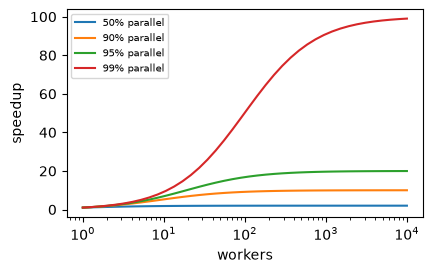

In [2]:
def amdahl_chart():
    n = np.logspace(0, 4, 40)
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    for p in [0.5, 0.9, 0.95, 0.99]:
        ax.semilogx(n, 1 / ((1 - p) + p / n), label=f"{int(p * 100)}% parallel")
    ax.set_xlabel("workers")
    ax.set_ylabel("speedup")
    ax.legend(fontsize=7)


amdahl_chart()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q8](#q8), [Q10](#q10), [Q15](#q15), [Q16](#q16), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 3: Replication and consistency

*Level: Core*

Copies add safety, but keeping them in step is hard.



**Replication lag.** A write at time 10 reaches a replica 5 seconds later. A read from that replica at time 14 misses it. So your app may not show what you just wrote: this is **eventual consistency**.



**Quorums.** With N copies, wait for W acknowledgements on write, and R on read. If **R + W &gt; N**, any read overlaps any write, so it must see the latest.



| N, W, R | Sees the latest? | Failures tolerated (write, read) |
| --- | --- | --- |
| 3, 2, 2 | yes | 1, 1 |
| 3, 1, 1 | no, but fast | 2, 2 |
| 5, 3, 3 | yes | 2, 2 |



**CAP theorem.** When a network splits machines apart (P), you must choose: refuse some requests to stay correct (**C**onsistency), or answer anyway and risk stale data (**A**vailability). A bank balance needs C; a social media like count can use A.



**Leaders.** Many systems choose one leader to order writes. A candidate needs a **strict majority**, so a split network can't elect two leaders: 3 of 5 wins, and 2–2 of 5 elects nobody. Failures are noticed through **heartbeats**: a worker silent for 30 seconds is presumed dead.



**Time is unreliable.** Clocks on different machines disagree, so timestamps can't always order events. **Vector clocks** keep one counter per machine. [1, 2] came before [1, 3], while [2, 1] and [1, 2] are concurrent: neither knew of the other.

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q3](#q3), [Q13](#q13), [Q5](#q5), [Q20](#q20), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 4: Rebalancing and delivery guarantees

*Level: Advanced*

**What happens when you add a machine?** With `key % n`, going from 4 to 5 machines moves **80%** of keys, and from 100 to 101 moves about 90%.



**Consistent hashing** places machines and keys on a ring, and each key goes to the next machine clockwise. Adding a machine only takes keys from its neighbour. In our test, going from 4 to 5 nodes moves 38% of keys rather than 80%. That's above the ideal 20%, as with so few points the ring is uneven. Real systems give each machine many **virtual nodes** to even it out.



**Delivery guarantees.** A consumer reads a message, processes it, and records progress. A crash can fall between those steps:



| Order | On a crash | Guarantee |
| --- | --- | --- |
| Record, then process | message lost | **at most once** |
| Process, then record | message repeated | **at least once** |
| Both atomically, or idempotent processing | looks like once | **exactly once** (effectively) |



With 5 messages and a crash at the third: recording first means one is lost, leaving 4 processed. Processing first means 6 processings, with one duplicate.



**The practical recipe: at-least-once delivery + idempotent processing = effectively exactly once.** Give each request an idempotency key, and apply each key once. With a, b, a, you apply 15 rather than 25.



You'll see all of this again in Kafka and Spark, because they're built on these ideas.

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q19](#q19), [Q12](#q12), [Q11](#q11). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
import bisect


<a id="q1"></a>
### Q1. Word Count With MapReduce

🟢 Warm-up · *The original big data idea*

Implement map (emit (word, 1)), shuffle (group by word) and reduce (sum). Return counts with sorted keys.

**Examples**

- `lines = ['a b a', 'b c']` → `{'a': 2, 'b': 2, 'c': 1}`

In [ ]:
def word_count(lines):
    """
    Implement map (emit (word, 1)), shuffle (group by word) and reduce (sum).
    Return counts with sorted keys.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(word_count, [
    ((['a b a', 'b c'],), {'a': 2, 'b': 2, 'c': 1}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Three explicit phases.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter` on one machine; the phases matter when data's spread over many.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Three explicit phases.

```python
def word_count(lines):
    mapped = []
    for line in lines:
        for word in line.split():
            mapped.append((word, 1))
    groups = {}
    for word, one in mapped:
        groups.setdefault(word, []).append(one)
    return {word: sum(groups[word]) for word in sorted(groups)}
```

**Cost:** O(w) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter` on one machine; the phases matter when data's spread over many.

```python
def word_count(lines):
    from collections import Counter
    return dict(sorted(Counter(w for l in lines for w in l.split()).items()))
```

**Cost:** O(w) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Three explicit phases. That costs O(w) time and O(k) space."

"I can do better: `Counter` on one machine; the phases matter when data's spread over many. That's O(w) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/word-count-with-mapreduce)

<a id="q2"></a>
### Q2. Hash Partitioning

🟢 Warm-up · *Where does each key live?*

Send each key to partition (sum of character codes) mod n. Return lists of keys per partition.

**Examples**

- `keys = ['a', 'b', 'c', 'a'], n = 2` → `[['b'], ['a', 'c', 'a']]`

In [ ]:
def hash_partition(keys, n):
    """
    Send each key to partition (sum of character codes) mod n. Return lists of
    keys per partition.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hash_partition, [
    ((['a', 'b', 'c', 'a'], 2), [['b'], ['a', 'c', 'a']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list of lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with a comprehension for the setup.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A list of lists.

```python
def hash_partition(keys, n):
    parts = []
    for _ in range(n):
        parts.append([])
    for k in keys:
        total = 0
        for ch in k:
            total += ord(ch)
        parts[total % n].append(k)
    return parts
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with a comprehension for the setup.

```python
def hash_partition(keys, n):
    parts = [[] for _ in range(n)]
    for k in keys:
        parts[sum(map(ord, k)) % n].append(k)
    return parts
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list of lists. That costs O(k) time and O(k) space."

"I can do better: Same, with a comprehension for the setup. That's O(k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/hash-partitioning)

<a id="q3"></a>
### Q3. Replication Lag: Stale Read?

🟢 Warm-up · *Eventually consistent*

A write happened at t\_write and reached a replica after lag. Return whether a read at t\_read sees it.

**Examples**

- `t_write = 10, lag = 5, t_read = 14` → `False`
- `t_write = 10, lag = 5, t_read = 15` → `True`

In [ ]:
def sees_write(t_write, lag, t_read):
    """
    A write happened at t_write and reached a replica after lag. Return whether
    a read at t_read sees it.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sees_write, [
    ((10, 5, 14), False),
    ((10, 5, 15), True),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute when it arrives.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One comparison.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute when it arrives.

```python
def sees_write(t_write, lag, t_read):
    arrives = t_write + lag
    return t_read >= arrives
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One comparison.

```python
def sees_write(t_write, lag, t_read):
    return t_read - t_write >= lag
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute when it arrives. That costs O(1) time and O(1) space."

"I can do better: One comparison. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/replication-lag-stale-read)

<a id="q4"></a>
### Q4. Chance of Failure at Scale

🟢 Warm-up · *Failure is normal*

If a machine fails with probability p per day, return the chance at least one of n fails, and expected failures a day, rounded to 4 decimals.

**Examples**

- `p = 0.001, n = 1000` → `(0.6323, 1.0)`
- `p = 0.001, n = 10` → `(0.01, 0.01)`

In [ ]:
def failure_chance(p, n):
    """
    If a machine fails with probability p per day, return the chance at least
    one of n fails, and expected failures a day, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(failure_chance, [
    ((0.001, 1000), (0.6323, 1.0)),
    ((0.001, 10), (0.01, 0.01)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply survival in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A power.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Multiply survival in a loop.

```python
def failure_chance(p, n):
    survive = 1.0
    for _ in range(n):
        survive *= 1 - p
    return (round(1 - survive, 4), round(p * n, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A power.

```python
def failure_chance(p, n):
    return (round(1 - (1 - p) ** n, 4), round(p * n, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply survival in a loop. That costs O(n) time and O(1) space."

"I can do better: A power. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/chance-of-failure-at-scale)

<a id="q5"></a>
### Q5. Heartbeats: Who's Dead?

🟢 Warm-up · *Detecting failures*

last maps a worker to its last heartbeat time. Return workers silent for longer than timeout at now, sorted.

**Examples**

- `last = {'a': 100, 'b': 50, 'c': 91}, now = 110, timeout = 30` → `['b']`

In [ ]:
def dead_workers(last, now, timeout):
    """
    last maps a worker to its last heartbeat time. Return workers silent for
    longer than timeout at now, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dead_workers, [
    (({'a': 100, 'b': 50, 'c': 91}, 110, 30), ['b']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A sorted comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def dead_workers(last, now, timeout):
    out = []
    for worker, t in last.items():
        if now - t > timeout:
            out.append(worker)
    return sorted(out)
```

**Cost:** O(w log w) time, O(w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A sorted comprehension.

```python
def dead_workers(last, now, timeout):
    return sorted(w for w, t in last.items() if now - t > timeout)
```

**Cost:** O(w log w) time, O(w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(w log w) time and O(w) space."

"I can do better: A sorted comprehension. That's O(w log w) time and O(w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/heartbeats-whos-dead)

<a id="q6"></a>
### Q6. Range Partitioning

🟡 Interview standard · *Sorted across machines*

Split boundaries define partitions: x goes to the first partition whose upper bound is greater than x. Return partition index for each value.

**Examples**

- `values = [5, 15, 25, 10], bounds = [10, 20]` → `[0, 1, 2, 1]`

In [ ]:
def range_partition(values, bounds):
    """
    Split boundaries define partitions: x goes to the first partition whose
    upper bound is greater than x. Return partition index for each value.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(range_partition, [
    (([5, 15, 25, 10], [10, 20]), [0, 1, 2, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan the boundaries.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`bisect`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan the boundaries.

```python
def range_partition(values, bounds):
    out = []
    for v in values:
        i = 0
        while i < len(bounds) and v >= bounds[i]:
            i += 1
        out.append(i)
    return out
```

**Cost:** O(n·b) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `bisect`.

```python
def range_partition(values, bounds):
    return [bisect.bisect_right(bounds, v) for v in values]
```

**Cost:** O(n log b) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan the boundaries. That costs O(n·b) time and O(n) space."

"I can do better: `bisect`. That's O(n log b) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/range-partitioning)

<a id="q7"></a>
### Q7. Measure Skew

🟡 Interview standard · *One slow partition slows everything*

Given partition sizes, return (largest ÷ average, rounded to 2 decimals; the job time as the largest, in seconds at rate rows per second).

**Examples**

- `sizes = [100, 100, 100, 100], rate = 10` → `(1.0, 10.0)`
- `sizes = [10, 10, 10, 370], rate = 10` → `(3.7, 37.0)`

In [ ]:
def skew(sizes, rate):
    """
    Given partition sizes, return (largest ÷ average, rounded to 2 decimals; the
    job time as the largest, in seconds at rate rows per second).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(skew, [
    (([100, 100, 100, 100], 10), (1.0, 10.0)),
    (([10, 10, 10, 370], 10), (3.7, 37.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Built-ins.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute by hand.

```python
def skew(sizes, rate):
    total = big = 0
    for s in sizes:
        total += s
        if s > big:
            big = s
    return (round(big / (total / len(sizes)), 2), big / rate)
```

**Cost:** O(p) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Built-ins.

```python
def skew(sizes, rate):
    return (round(max(sizes) * len(sizes) / sum(sizes), 2), max(sizes) / rate)
```

**Cost:** O(p) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute by hand. That costs O(p) time and O(1) space."

"I can do better: Built-ins. That's O(p) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/measure-skew)

<a id="q8"></a>
### Q8. Salting a Hot Key

🟡 Interview standard · *Break up skew*

Split a hot key's rows across s sub-keys in turn ('key#0', 'key#1', …). Return row counts per sub-key, sorted by name.

**Examples**

- `rows = ['us', 'us', 'us', 'us', 'us', 'us', 'us'], s = 3` → `{'us#0': 3, 'us#1': 2, 'us#2': 2}`

In [ ]:
def salt(rows, s):
    """
    Split a hot key's rows across s sub-keys in turn ('key#0', 'key#1', …).
    Return row counts per sub-key, sorted by name.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(salt, [
    ((['us', 'us', 'us', 'us', 'us', 'us', 'us'], 3), {'us#0': 3, 'us#1': 2, 'us#2': 2}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary with a counter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A dictionary with a counter.

```python
def salt(rows, s):
    counts = {}
    for i, r in enumerate(rows):
        key = f"{r}#{i % s}"
        counts[key] = counts.get(key, 0) + 1
    return dict(sorted(counts.items()))
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter`.

```python
def salt(rows, s):
    from collections import Counter
    return dict(sorted(Counter(f"{r}#{i % s}" for i, r in enumerate(rows)).items()))
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary with a counter. That costs O(n) time and O(s) space."

"I can do better: `Counter`. That's O(n) time and O(s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/salting-a-hot-key)

<a id="q9"></a>
### Q9. Quorum Reads and Writes

🟡 Interview standard · *R + W &gt; N*

With N replicas, W write acks and R read acks: return whether reads must see the latest write, and how many failures writes and reads each tolerate.

**Examples**

- `n = 3, w = 2, r = 2` → `(True, 1, 1)`
- `n = 3, w = 1, r = 1` → `(False, 2, 2)`
- `n = 5, w = 3, r = 3` → `(True, 2, 2)`

In [ ]:
def quorum(n, w, r):
    """
    With N replicas, W write acks and R read acks: return whether reads must see
    the latest write, and how many failures writes and reads each tolerate.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(quorum, [
    ((3, 2, 2), (True, 1, 1)),
    ((3, 1, 1), (False, 2, 2)),
    ((5, 3, 3), (True, 2, 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check by reasoning.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A one-line formula.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Check by reasoning.

```python
def quorum(n, w, r):
    overlap = r + w > n
    write_fail = n - w
    read_fail = n - r
    return (overlap, write_fail, read_fail)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A one-line formula.

```python
def quorum(n, w, r):
    return (r + w > n, n - w, n - r)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check by reasoning. That costs O(1) time and O(1) space."

"I can do better: A one-line formula. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/quorum-reads-and-writes)

<a id="q10"></a>
### Q10. Amdahl's Law

🟡 Interview standard · *Why more machines stop helping*

With parallel share p and n workers, speedup = 1 / ((1 − p) + p/n). Return it rounded to 2 decimals.

**Examples**

- `p = 0.95, n = 10` → `6.9`
- `p = 0.95, n = 1000` → `19.63`
- `p = 0.5, n = 1000` → `2.0`

In [ ]:
def amdahl(p, n):
    """
    With parallel share p and n workers, speedup = 1 / ((1 − p) + p/n). Return
    it rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(amdahl, [
    ((0.95, 10), 6.9),
    ((0.95, 1000), 19.63),
    ((0.5, 1000), 2.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the serial and parallel parts.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One formula.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute the serial and parallel parts.

```python
def amdahl(p, n):
    serial = 1 - p
    parallel = p / n
    return round(1 / (serial + parallel), 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One formula.

```python
def amdahl(p, n):
    return round(1 / ((1 - p) + p / n), 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the serial and parallel parts. That costs O(1) time and O(1) space."

"I can do better: One formula. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/amdahls-law)

<a id="q11"></a>
### Q11. Retries Without Double Effects

🟡 Interview standard · *Idempotency keys*

Requests are (key, amount); retries repeat a key. Apply each key once, and return (total, duplicates ignored).

**Examples**

- `requests = [('a', 10), ('b', 5), ('a', 10)]` → `(15, 1)`

In [ ]:
def idempotent_total(requests):
    """
    Requests are (key, amount); retries repeat a key. Apply each key once, and
    return (total, duplicates ignored).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(idempotent_total, [
    (([('a', 10), ('b', 5), ('a', 10)],), (15, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list of seen keys.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A set.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A list of seen keys.

```python
def idempotent_total(requests):
    seen, total, dupes = [], 0, 0
    for key, amount in requests:
        if key in seen:
            dupes += 1
        else:
            seen.append(key)
            total += amount
    return (total, dupes)
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A set.

```python
def idempotent_total(requests):
    first = {}
    for key, amount in requests:
        first.setdefault(key, amount)
    return (sum(first.values()), len(requests) - len(first))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list of seen keys. That costs O(n²) time and O(n) space."

"I can do better: A set. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/retries-without-double-effects)

<a id="q12"></a>
### Q12. Delivery Semantics

🟡 Interview standard · *At most, at least, exactly once*

A consumer handles messages 1 to n and crashes around message c. Committing before processing loses the next message; committing after processing repeats message c. Return (messages processed at least once with commit-before, total processings with commit-after).

**Examples**

- `n = 5, c = 3` → `(4, 6)`

In [ ]:
def delivery(n, c):
    """
    A consumer handles messages 1 to n and crashes around message c. Committing
    before processing loses the next message; committing after processing
    repeats message c. Return (messages processed at least once with commit-
    before, total processings with commit-after).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(delivery, [
    ((5, 3), (4, 6)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simulate each order.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Reason it out: at-most-once loses none of the done ones here, and at-least-once does one extra.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Simulate each order.

```python
def delivery(n, c):
    # commit-after: crash before committing c, so c is read and processed again
    after = 0
    committed = 0
    for m in range(1, c + 1):
        after += 1
        if m < c:
            committed = m
    for m in range(committed + 1, n + 1):
        after += 1
    # commit-before: message c+1 was committed but never processed
    before = set(range(1, c + 1)) | set(range(c + 2, n + 1))
    return (len(before), after)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Reason it out: at-most-once loses none of the done ones here, and at-least-once does one extra.

```python
def delivery(n, c):
    return (n - 1, n + 1)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simulate each order. That costs O(n) time and O(n) space."

"I can do better: Reason it out: at-most-once loses none of the done ones here, and at-least-once does one extra. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/delivery-semantics)

<a id="q13"></a>
### Q13. Leader Election by Majority

🟡 Interview standard · *Who's in charge?*

Given votes per candidate and total nodes, return the winner with a strict majority, else None. A majority prevents two leaders in a split.

**Examples**

- `votes = {'a': 3, 'b': 2}, nodes = 5` → `'a'`
- `votes = {'a': 2, 'b': 2}, nodes = 5` → `None`

In [ ]:
def leader(votes, nodes):
    """
    Given votes per candidate and total nodes, return the winner with a strict
    majority, else None. A majority prevents two leaders in a split.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leader, [
    (({'a': 3, 'b': 2}, 5), 'a'),
    (({'a': 2, 'b': 2}, 5), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`next` with a generator.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def leader(votes, nodes):
    for name, count in votes.items():
        if count > nodes / 2:
            return name
    return None
```

**Cost:** O(c) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `next` with a generator.

```python
def leader(votes, nodes):
    return next((c for c, v in votes.items() if 2 * v > nodes), None)
```

**Cost:** O(c) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(c) time and O(1) space."

"I can do better: `next` with a generator. That's O(c) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/leader-election-by-majority)

<a id="q14"></a>
### Q14. Reassign Tasks After a Failure

🟡 Interview standard · *Lineage rebuilds work*

tasks maps a task to its worker. When a worker dies, reassign its tasks to the least-loaded workers in turn. Return the new mapping, sorted.

**Examples**

- `tasks = {'t1': 'a', 't2': 'a', 't3': 'b', 't4': 'c'}, dead = 'a'` → `{'t1': 'b', 't2': 'c', 't3': 'b', 't4': 'c'}`

In [ ]:
def reassign(tasks, dead):
    """
    tasks maps a task to its worker. When a worker dies, reassign its tasks to
    the least-loaded workers in turn. Return the new mapping, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(reassign, [
    (({'t1': 'a', 't2': 'a', 't3': 'b', 't4': 'c'}, 'a'), {'t1': 'b', 't2': 'c', 't3': 'b', 't4': 'c'}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Recount the load each time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A heap of (load, worker).

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Recount the load each time.

```python
def reassign(tasks, dead):
    out = dict(tasks)
    alive = sorted({w for w in tasks.values() if w != dead})
    for t in sorted(tasks):
        if tasks[t] == dead:
            loads = {w: sum(1 for x in out.values() if x == w) for w in alive}
            out[t] = min(alive, key=lambda w: (loads[w], w))
    return dict(sorted(out.items()))
```

**Cost:** O(t²) time, O(t) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A heap of (load, worker).

```python
def reassign(tasks, dead):
    import heapq
    from collections import Counter
    loads = Counter(w for w in tasks.values() if w != dead)
    heap = [(n, w) for w, n in loads.items()]
    heapq.heapify(heap)
    out = dict(tasks)
    for t in sorted(k for k, w in tasks.items() if w == dead):
        n, w = heapq.heappop(heap)
        out[t] = w
        heapq.heappush(heap, (n + 1, w))
    return dict(sorted(out.items()))
```

**Cost:** O(t log w) time, O(w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Recount the load each time. That costs O(t²) time and O(t) space."

"I can do better: A heap of (load, worker). That's O(t log w) time and O(w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/reassign-tasks-after-a-failure)

<a id="q15"></a>
### Q15. Speculative Execution

🟡 Interview standard · *Beat the stragglers*

Tasks have run times. The job takes the longest. If tasks above limit are re-run on a fresh worker taking backup seconds, the finish is the smaller. Return (time before, time after), with each task's new time min(t, limit + backup).

**Examples**

- `times = [10, 11, 100], limit = 20, backup = 12` → `(100, 32)`

In [ ]:
def speculative(times, limit, backup):
    """
    Tasks have run times. The job takes the longest. If tasks above limit are
    re-run on a fresh worker taking backup seconds, the finish is the smaller.
    Return (time before, time after), with each task's new time min(t, limit +
    backup).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(speculative, [
    (([10, 11, 100], 20, 12), (100, 32)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop, computing each task's time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A generator with `max`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop, computing each task's time.

```python
def speculative(times, limit, backup):
    before = after = 0
    for t in times:
        before = max(before, t)
        new = t if t <= limit else min(t, limit + backup)
        after = max(after, new)
    return (before, after)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A generator with `max`.

```python
def speculative(times, limit, backup):
    return (max(times), max(t if t <= limit else min(t, limit + backup) for t in times))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop, computing each task's time. That costs O(n) time and O(1) space."

"I can do better: A generator with `max`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/speculative-execution)

<a id="q16"></a>
### Q16. Shuffle Volume

🟡 Interview standard · *Network is the bottleneck*

With hash partitioning over m machines, a share of (m − 1)/m of the data must cross the network. Return GB moved and minutes at gbps gigabits per second in total, rounded to 2 decimals.

**Examples**

- `gb = 1000, m = 10, gbps = 10` → `(900.0, 12.0)`

In [ ]:
def shuffle_cost(gb, m, gbps):
    """
    With hash partitioning over m machines, a share of (m − 1)/m of the data
    must cross the network. Return GB moved and minutes at gbps gigabits per
    second in total, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(shuffle_cost, [
    ((1000, 10, 10), (900.0, 12.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step by step, watching bits vs bytes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formulas.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Step by step, watching bits vs bytes.

```python
def shuffle_cost(gb, m, gbps):
    moved = gb * (m - 1) / m
    gigabits = moved * 8
    seconds = gigabits / gbps
    return (round(moved, 2), round(seconds / 60, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Formulas.

```python
def shuffle_cost(gb, m, gbps):
    moved = gb * (m - 1) / m
    return (round(moved, 2), round(moved * 8 / gbps / 60, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step by step, watching bits vs bytes. That costs O(1) time and O(1) space."

"I can do better: Formulas. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/shuffle-volume)

<a id="q17"></a>
### Q17. Broadcast or Shuffle?

🟡 Interview standard · *The cost of a join*

Broadcasting copies the small table to each of m machines: small × m. Shuffling moves (m − 1)/m of both tables. Return the cheaper strategy and its GB moved, rounded to 2 decimals.

**Examples**

- `small = 1, large = 1000, m = 10` → `['broadcast', 10]`
- `small = 800, large = 1000, m = 10` → `['shuffle', 1620.0]`

In [ ]:
def join_network(small, large, m):
    """
    Broadcasting copies the small table to each of m machines: small × m.
    Shuffling moves (m − 1)/m of both tables. Return the cheaper strategy and
    its GB moved, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(join_network, [((1, 1000, 10), ['broadcast', 10]), ((800, 1000, 10), ['shuffle', 1620.0])], post=list)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute both, then compare.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`min` over pairs.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute both, then compare.

```python
def join_network(small, large, m):
    broadcast = small * m
    shuffle = (small + large) * (m - 1) / m
    if broadcast < shuffle:
        return ("broadcast", round(broadcast, 2))
    return ("shuffle", round(shuffle, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `min` over pairs.

```python
def join_network(small, large, m):
    return min([("broadcast", round(small * m, 2)), ("shuffle", round((small + large) * (m - 1) / m, 2))], key=lambda x: x[1])
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute both, then compare. That costs O(1) time and O(1) space."

"I can do better: `min` over pairs. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/broadcast-or-shuffle)

<a id="q18"></a>
### Q18. Rehash Cost: Mod vs Consistent

🔴 Stretch · *Adding a machine*

Keys are 0 to n−1. Return the share that move when going from a to b machines with id % machines, rounded to 4 decimals.

**Examples**

- `n = 1000, a = 4, b = 5` → `0.8`
- `n = 1000, a = 100, b = 101` → `0.9`

In [ ]:
def moved_share(n, a, b):
    """
    Keys are 0 to n−1. Return the share that move when going from a to b
    machines with id % machines, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(moved_share, [
    ((1000, 4, 5), 0.8),
    ((1000, 100, 101), 0.9),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A generator with sum.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Count in a loop.

```python
def moved_share(n, a, b):
    moved = 0
    for k in range(n):
        if k % a != k % b:
            moved += 1
    return round(moved / n, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A generator with sum.

```python
def moved_share(n, a, b):
    return round(sum(k % a != k % b for k in range(n)) / n, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a loop. That costs O(n) time and O(1) space."

"I can do better: A generator with sum. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/rehash-cost-mod-vs-consistent)

<a id="q19"></a>
### Q19. Consistent Hashing

🔴 Stretch · *Move little when machines change*

Place nodes on a ring at hash(node) % 360 (hash = md5 as an integer). A key belongs to the first node clockwise. Return the share of keys 'k0'..'k{n−1}' that move when a node is added, rounded to 2 decimals.

**Examples**

- `nodes = ['a', 'b', 'c', 'd'], new = 'e', n = 1000` → `0.38`

In [ ]:
import hashlib

def ring_moved(nodes, new, n):
    """
    Place nodes on a ring at hash(node) % 360 (hash = md5 as an integer). A key
    belongs to the first node clockwise. Return the share of keys 'k0'..'k{n−1}'
    that move when a node is added, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ring_moved, [
    ((['a', 'b', 'c', 'd'], 'e', 1000), 0.38),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan nodes for each key.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Sort the ring, and use binary search.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan nodes for each key.

```python
def ring_moved(nodes, new, n):
    def h2(s):
        return int(hashlib.md5(s.encode()).hexdigest(), 16) % 360

    def owner(key, members):
        pos = h2(key)
        best, best_d = None, 999
        for m in members:
            d = (h2(m) - pos) % 360
            if d < best_d or (d == best_d and m < best):
                best, best_d = m, d
        return best
    moved = sum(owner(f"k{i}", nodes) != owner(f"k{i}", nodes + [new]) for i in range(n))
    return round(moved / n, 2)
```

**Cost:** O(n·m) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Sort the ring, and use binary search.

```python
def ring_moved(nodes, new, n):
    def h2(s):
        return int(hashlib.md5(s.encode()).hexdigest(), 16) % 360

    def ring(members):
        return sorted((h2(m), m) for m in members)

    def owner(key, r):
        i = bisect.bisect_left(r, (h2(key), ""))
        return r[i % len(r)][1]
    a, b = ring(nodes), ring(nodes + [new])
    return round(sum(owner(f"k{i}", a) != owner(f"k{i}", b) for i in range(n)) / n, 2)
```

**Cost:** O((n + m) log m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan nodes for each key. That costs O(n·m) time and O(m) space."

"I can do better: Sort the ring, and use binary search. That's O((n + m) log m) time and O(m) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `nodes = ['a', 'b', 'c', 'd'], new = 'e', n = 1000`

1. h2() returns 217
2. h2() returns 103
3. h2() returns 43
4. h2() returns 213
5. ring() returns [(43, 'c'), (103, 'b'), (213, 'd'), (...
6. h2() returns 217
7. h2() returns 103
8. h2() returns 43
9. h2() returns 213
10. h2() returns 346
11. ring() returns [(43, 'c'), (103, 'b'), (213, 'd'), (...
12. h2() returns 325
13. owner() returns 'c'
14. h2() returns 325
15. owner() returns 'e'

*…and so on.*

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/consistent-hashing)

<a id="q20"></a>
### Q20. Vector Clocks: Which Came First?

🔴 Stretch · *No shared clock*

Compare two vector clocks (lists). Return 'before', 'after', 'equal' or 'concurrent'.

**Examples**

- `a = [1, 2], b = [1, 3]` → `'before'`
- `a = [2, 1], b = [1, 2]` → `'concurrent'`
- `a = [1, 1], b = [1, 1]` → `'equal'`

In [ ]:
def clock_order(a, b):
    """
    Compare two vector clocks (lists). Return 'before', 'after', 'equal' or
    'concurrent'.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(clock_order, [
    (([1, 2], [1, 3]), 'before'),
    (([2, 1], [1, 2]), 'concurrent'),
    (([1, 1], [1, 1]), 'equal'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track flags in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`all` twice.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Track flags in a loop.

```python
def clock_order(a, b):
    smaller = bigger = False
    for x, y in zip(a, b):
        if x < y:
            smaller = True
        if x > y:
            bigger = True
    if smaller and bigger:
        return "concurrent"
    if smaller:
        return "before"
    if bigger:
        return "after"
    return "equal"
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `all` twice.

```python
def clock_order(a, b):
    le, ge = all(x <= y for x, y in zip(a, b)), all(x >= y for x, y in zip(a, b))
    return "equal" if le and ge else "before" if le else "after" if ge else "concurrent"
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track flags in a loop. That costs O(n) time and O(1) space."

"I can do better: `all` twice. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/distributed-systems/vector-clocks-which-came-first)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Scale up vs scale out?</b></summary>

Scale up buys a bigger machine, which is simple but limited and costly. Scale out adds machines, which scales far, but brings partitioning, replication and failures.

</details>

<details>
<summary><b>2. Partitioning vs replication?</b></summary>

Partitioning splits data across machines, for scale. Replication copies data, for safety and read capacity. Most systems use both.

</details>

<details>
<summary><b>3. Explain the CAP theorem.</b></summary>

During a network partition, a system must give up either consistency or availability. Without a partition you can have both, though you still trade latency against consistency.

</details>

<details>
<summary><b>4. What is eventual consistency?</b></summary>

Replicas may disagree for a while, but converge once updates stop arriving.

</details>

<details>
<summary><b>5. What is data skew?</b></summary>

Uneven data across partitions. The largest partition determines job time, wasting the rest of the cluster.

</details>

<details>
<summary><b>6. At-most-once, at-least-once, exactly-once?</b></summary>

Messages can be lost, repeated, or effectively processed once. In practice, exactly-once usually means at-least-once delivery with idempotent or transactional processing.

</details>

<details>
<summary><b>7. Why is consistent hashing useful?</b></summary>

When machines join or leave, only a small share of keys move, rather than nearly all of them as with modulo hashing.

</details>

<details>
<summary><b>8. Scenario: you doubled the cluster but the job only got 10% faster. Why?</b></summary>

A serial bottleneck (Amdahl), skew in one partition, a slow source or sink, or network shuffle limits. Find the bottleneck before adding hardware.

</details>

<details>
<summary><b>9. Scenario: a job is stuck at 99% for an hour. What's happening?</b></summary>

Almost certainly skew, or a straggler. Look at per-task data sizes. Fix hot keys by salting, broadcasting or filtering NULL keys.

</details>

<details>
<summary><b>10. Scenario: users sometimes don't see the data they just saved. Why?</b></summary>

Reads go to a replica with lag. Read from the leader after a write, use a read-your-writes approach, or increase quorums.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why one computer isn't enough
- [ ] I can explain: Skew, stragglers and why more machines stop helping
- [ ] I can explain: Replication and consistency
- [ ] I can explain: Rebalancing and delivery guarantees

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Shuffle Volume
- [ ] [Q17](#q17) Broadcast or Shuffle?
- [ ] [Q18](#q18) Rehash Cost: Mod vs Consistent
- [ ] [Q19](#q19) Consistent Hashing
- [ ] [Q20](#q20) Vector Clocks: Which Came First?

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.